In [10]:
# 1. Importando e carregando o dataset processado
import pandas as pd

df = pd.read_csv('../data/processed/dataset_preprocessed.csv')

# 2. Criando o alvo (y): 1 se o tempo foi maior que a mediana (atrasado), 0 caso contrário
mediana_tempo = df['actual_delivery_time_minutes'].median()
df['atrasado'] = (df['actual_delivery_time_minutes'] > mediana_tempo).astype(int)

print(f"Total de pedidos na base: {df.shape[0]}")
print(f"Pedidos considerados atrasados (1): {df['atrasado'].sum()}")

Total de pedidos na base: 49132
Pedidos considerados atrasados (1): 23096


In [11]:
# 1. Definindo o alvo que queremos prever (se atrasou ou não)
y = df['atrasado']

# 2. Definindo as características (X) que o modelo vai usar para prever
# Selecionamos apenas os números e removemos o tempo real de entrega e o alvo
X = df.select_dtypes(include=['number']).drop(columns=['actual_delivery_time_minutes', 'atrasado'], errors='ignore')

print(f"Total de linhas para treino: {X.shape[0]}")
print(f"Total de colunas (características) usadas: {X.shape[1]}")

Total de linhas para treino: 49132
Total de colunas (características) usadas: 32


In [12]:
# 3. Dividindo os dados em Treino (80%) e Teste (20%)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Linhas para o modelo estudar (treino): {X_train.shape[0]}")
print(f"Linhas para a prova final (teste): {X_test.shape[0]}")

Linhas para o modelo estudar (treino): 39305
Linhas para a prova final (teste): 9827


In [13]:
# 4. Importando, escalando os dados via Pipeline e treinando o modelo de Regressão Logística
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# Pipeline com StandardScaler (ajustado estritamente no treino) e o estimador com seed fixa
model_class = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# O modelo estuda os padrões usando os dados de treino
model_class.fit(X_train, y_train)

# 5. Gerando previsões com a "prova final" (dados de teste)
y_pred = model_class.predict(X_test)

# Calculando a taxa de acerto (Acurácia)
acuracia = accuracy_score(y_test, y_pred)

print(f"Acurácia do Modelo de Classificação: {acuracia * 100:.2f}%")

Acurácia do Modelo de Classificação: 94.98%


In [14]:
# 5. Avaliação detalhada do modelo de Classificação
from sklearn.metrics import classification_report, confusion_matrix

# Gerando o relatório detalhado de acertos e erros por categoria (0 = No Prazo, 1 = Atrasado)
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred))

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      5231
           1       0.95      0.95      0.95      4596

    accuracy                           0.95      9827
   macro avg       0.95      0.95      0.95      9827
weighted avg       0.95      0.95      0.95      9827



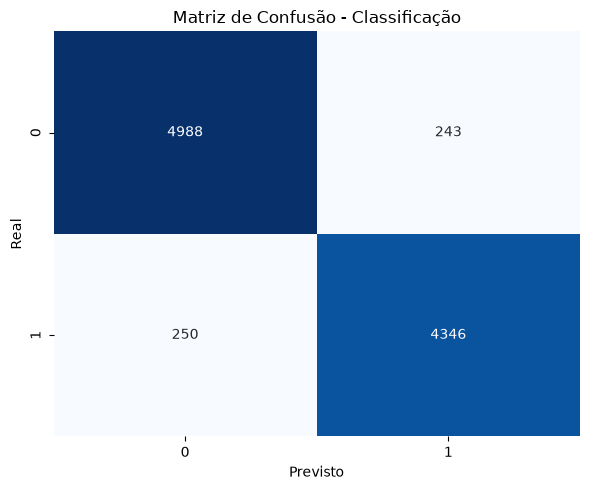

In [15]:
import sys
import os
sys.path.append(os.path.abspath('..'))

from src.visualization import plot_confusion_matrix

plot_confusion_matrix(y_test, y_pred)

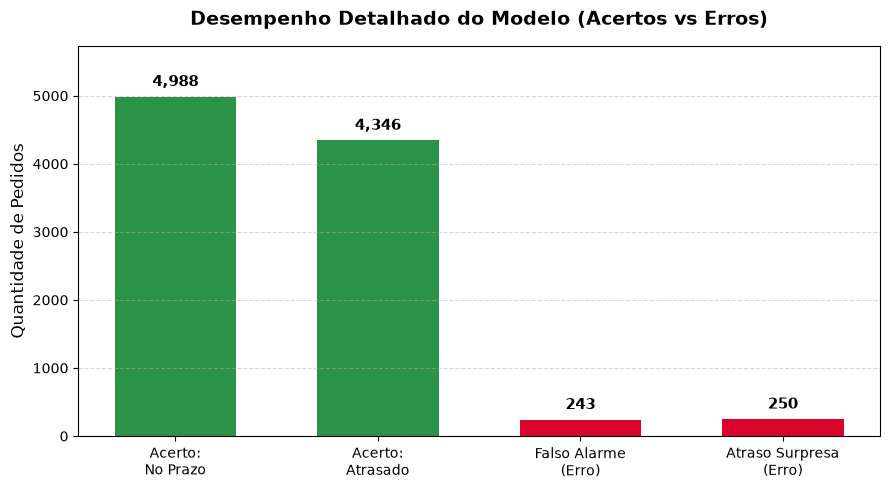

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import os

# Garantindo que a pasta de destino exista
os.makedirs('../reports/figures', exist_ok=True)

# Extraindo os valores diretamente das previsões do modelo (y_test e y_pred)
cm = confusion_matrix(y_test, y_pred)
acerto_no_prazo = cm[0, 0]    # Real 0, Previsto 0
falso_alarme = cm[0, 1]       # Real 0, Previsto 1
atraso_surpresa = cm[1, 0]    # Real 1, Previsto 0
acerto_atrasado = cm[1, 1]    # Real 1, Previsto 1

# Definindo as categorias e os valores correspondentes
categorias = ['Acerto:\nNo Prazo', 'Acerto:\nAtrasado', 'Falso Alarme\n(Erro)', 'Atraso Surpresa\n(Erro)']
valores = [acerto_no_prazo, acerto_atrasado, falso_alarme, atraso_surpresa]

# Cores: Tons de verde para acertos e tons de vermelho para erros
cores = ['#2b9348', '#2b9348', '#d90429', '#d90429']

plt.figure(figsize=(9, 5))
bars = plt.bar(categorias, valores, color=cores, width=0.6)

# Adicionando os números exatos em cima de cada barra
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'{yval:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Desempenho Detalhado do Modelo (Acertos vs Erros)', fontsize=14, pad=15, fontweight='bold')
plt.ylabel('Quantidade de Pedidos', fontsize=12)
plt.ylim(0, max(valores) * 1.15) # Margem superior para o texto não cortar
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

# Salvando a figura em alta resolução na pasta de relatórios
plt.savefig('../reports/figures/classification_bar_chart.png', dpi=300, bbox_inches='tight')

plt.show()